# ДЗ 4. Система мониторинга ML-модели

**Курс:** «Бизнес-применение машинного обучения»

## Задание

Постройте систему мониторинга кредитного скоринга на датасете `credit-g`:

| № | Шаг | Что делаем |
|---|-----|------------|
| 01 | Данные | `sklearn.datasets.fetch_openml("credit-g")` |
| 02 | Модель | обучаем CatBoost, считаем F1 |
| 03 | Дрифт | сдвиг `age` +5 лет, изменение распределения целевых классов |
| 04 | Evidently | запускаем отчёт, находим дрифт |
| 05 | Fairness | считаем метрики справедливости по признаку `sex` |
| 06 | Prometheus | экспортируем F1, настраиваем алерт на падение |

## Что получится в результате

- `artifacts/evidently_drift_report.html` — интерактивный отчёт Evidently;
- `artifacts/figures/*.png` — графики для отчёта и презентации;
- `artifacts/metrics.json` — все метрики в машинночитаемом виде;
- `prometheus/prometheus.yml` и `prometheus/alerts.yml` — конфигурация мониторинга;
- `src/metrics_exporter.py` — экспортёр метрик, который скрейпит Prometheus.

> **Как запускать:** ноутбук рассчитан на работу из корня проекта
> (`ДЗ 4`), библиотеки лежат в локальной папке `.pylibs` и подхватываются
> в первой ячейке. Полный прогон занимает ~1–2 минуты.


### Окружение и настройка

In [1]:
%matplotlib inline
import json
import subprocess
import sys
import time
import urllib.request
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- локальные библиотеки проекта (не трогаем системный Python) -------------
ROOT = Path.cwd()
LIB = ROOT / ".pylibs"
if LIB.exists() and str(LIB) not in sys.path:
    sys.path.insert(0, str(LIB))

ART = ROOT / "artifacts"
DATA = ART / "data"
FIG = ART / "figures"
SHOTS = ART / "screenshots"
PROM = ROOT / "prometheus"
for _d in (ART, DATA, FIG, SHOTS, PROM):
    _d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "target"        # целевая переменная: good / bad
POSITIVE = "bad"         # 1 = клиент не вернёт кредит (положительный класс модели)
FAVOURABLE = "good"      # благоприятный исход для fairness: кредит одобрен
PROTECTED = "sex"        # защищённый признак

np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

import catboost
import sklearn

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("catboost    :", catboost.__version__)
print("evidently   :", version("evidently"))
print("prometheus_client:", version("prometheus_client"))
print("Проект      :", ROOT)


Python      : 3.12.14
pandas      : 2.3.3
scikit-learn: 1.9.1
catboost    : 1.2.10
evidently   : 0.7.23
prometheus_client: 0.26.0
Проект      : C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4


## Шаг 1. Данные: `credit-g`

Классический датасет кредитного скоринга (OpenML id 31, German Credit):
1000 клиентов, 20 признаков (срок кредита, сумма, история платежей, возраст, …),
целевая переменная `class` — вернёт клиент кредит (`good`) или нет (`bad`).

Датасет загружается через `fetch_openml` и кэшируется в `artifacts/data/credit_g.csv`,
чтобы ноутбук можно было перезапустить без интернета.

In [2]:
from sklearn.datasets import fetch_openml

CSV_PATH = DATA / "credit_g.csv"

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source = "локальный кэш (повторный запуск)"
else:
    bunch = fetch_openml("credit-g", version=1, as_frame=True, parser="auto")
    df = bunch.frame.rename(columns={"class": TARGET})
    df.to_csv(CSV_PATH, index=False)
    source = "OpenML (api.openml.org)"

print(f"Источник данных: {source}")
print(f"Размер: {df.shape[0]} строк × {df.shape[1] - 1} признаков")
df.head()

Источник данных: локальный кэш (повторный запуск)
Размер: 1000 строк × 20 признаков


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
# Бинарная целевая переменная: 1 = bad (дефолт), 0 = good
df[TARGET] = (df[TARGET] == POSITIVE).astype(int)

# В credit-g нет колонки sex: пол зашит в personal_status.
# Разворачиваем его в отдельный бинарный признак — он нужен для fairness-аудита
# и НЕ подаётся в модель, чтобы не строить модель на защищённом признаке.
SEX_MAP = {
    "male div/sep": "male",
    "male single": "male",
    "male mar/wid": "male",
    "female div/dep/mar": "female",
}
df[PROTECTED] = df["personal_status"].map(SEX_MAP)

print("Пропуски в sex:", df[PROTECTED].isna().sum())
print("\nДоли классов (1 = bad):")
print(df[TARGET].value_counts(normalize=True).round(3).to_string())
print("\nГруппы по полу:")
print(df[PROTECTED].value_counts().to_string())
print("\nВозраст: min=%d, median=%.0f, max=%d" % (df.age.min(), df.age.median(), df.age.max()))
df[[TARGET, PROTECTED, "age", "credit_amount"]].describe().round(1)

Пропуски в sex: 0

Доли классов (1 = bad):
target
0    0.7
1    0.3

Группы по полу:
sex
male      690
female    310

Возраст: min=19, median=33, max=75


,target,age,credit_amount
count,1000.0,1000.0,1000.0
mean,0.3,35.5,3271.3
std,0.5,11.4,2822.7
min,0.0,19.0,250.0
25%,0.0,27.0,1365.5
50%,0.0,33.0,2319.5
75%,1.0,42.0,3972.2
max,1.0,75.0,18424.0


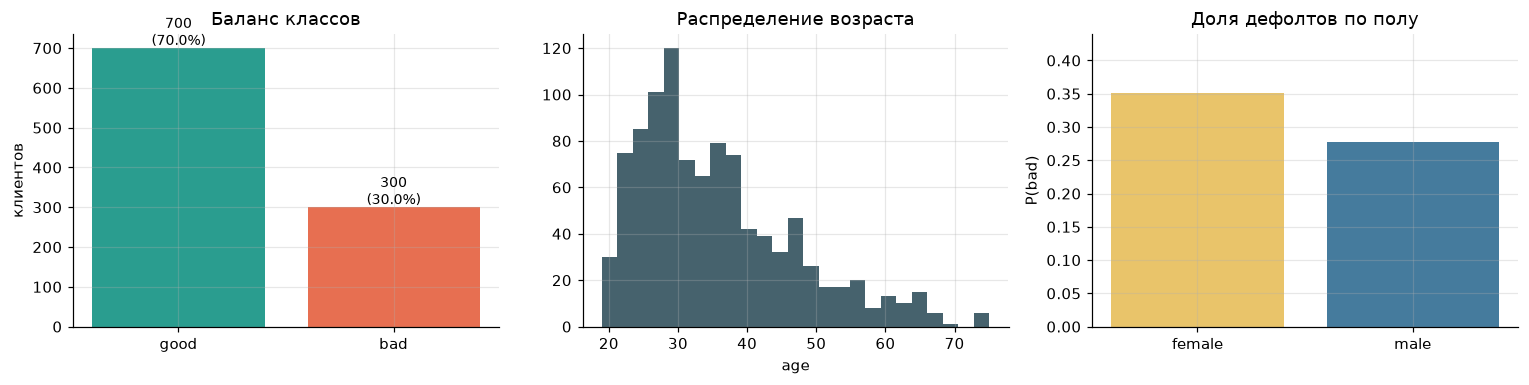

Сохранено: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\artifacts\figures\eda_overview.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

counts = df[TARGET].map({0: "good", 1: "bad"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#2a9d8f", "#e76f51"])
axes[0].set_title("Баланс классов")
axes[0].set_ylabel("клиентов")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v}\n({v / len(df):.1%})", ha="center", fontsize=9)

axes[1].hist(df["age"], bins=25, color="#264653", alpha=0.85)
axes[1].set_title("Распределение возраста")
axes[1].set_xlabel("age")

rate = df.groupby(PROTECTED)[TARGET].mean()
axes[2].bar(rate.index, rate.values, color=["#e9c46a", "#457b9d"])
axes[2].set_title("Доля дефолтов по полу")
axes[2].set_ylabel("P(bad)")
axes[2].set_ylim(0, max(rate.values) * 1.25)

fig.tight_layout()
fig.savefig(FIG / "eda_overview.png", bbox_inches="tight")
plt.show()
print("Сохранено:", FIG / "eda_overview.png")

## Шаг 2. Модель: CatBoost

Разделяем выборку 70/30 со стратификацией по целевой переменной.
Категориальные признаки передаём CatBoost «нативно» (`cat_features`), без one-hot —
именно так библиотека обычно и применяется в продакшене на табличных данных.

Целевая метрика — **F1 по классу `bad`** (дефолт клиента): именно она дальше
уезжает в Prometheus и по ней настраивается алерт.

In [5]:
from sklearn.model_selection import train_test_split

FEATURES = [c for c in df.columns if c not in (TARGET, PROTECTED)]
X = df[FEATURES].copy()
y = df[TARGET].to_numpy()
groups = df[PROTECTED].reset_index(drop=True)

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y,
)

CAT_FEATURES = [c for c in FEATURES if str(X[c].dtype) in ("category", "object")]
print(f"train: {X_train.shape[0]}, test: {X_test.shape[0]}")
print(f"категориальных признаков: {len(CAT_FEATURES)} из {len(FEATURES)}")
print("доля bad в train: %.3f, в test: %.3f" % (y_train.mean(), y_test.mean()))

train: 700, test: 300
категориальных признаков: 13 из 20
доля bad в train: 0.300, в test: 0.300


In [6]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations=600,
    learning_rate=0.05,
    depth=4,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=RANDOM_STATE,
    od_type="Iter",
    od_wait=50,
    verbose=100,
    allow_writing_files=False,
)

model.fit(
    X_train, y_train,
    cat_features=CAT_FEATURES,
    eval_set=(X_test, y_test),
    use_best_model=True,
)

print(f"\nДеревьев в финальной модели: {model.tree_count_}")
print(f"Лучшая итерация: {model.get_best_iteration()}")

0:	learn: 0.1557377	test: 0.2105263	best: 0.2105263 (0)	total: 68.4ms	remaining: 40.9s


100:	learn: 0.5893417	test: 0.4817518	best: 0.4927536 (99)	total: 1.14s	remaining: 5.65s


200:	learn: 0.7492958	test: 0.5503356	best: 0.5637584 (188)	total: 2.18s	remaining: 4.32s


Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.5882352941
bestIteration = 243

Shrink model to first 244 iterations.

Деревьев в финальной модели: 244
Лучшая итерация: 243


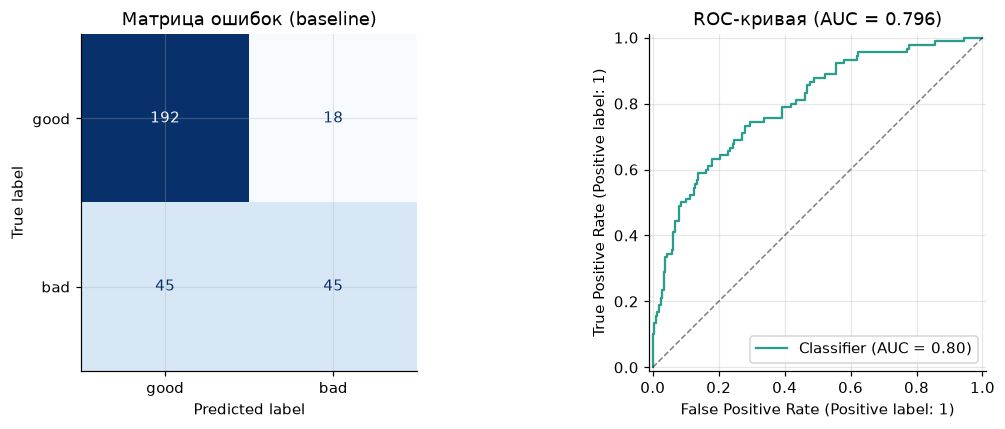

Модель сохранена: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\artifacts\model\catboost_credit_g.cbm


,N,P(bad),F1,Precision,Recall,ROC AUC,Accuracy
0,300,0.3,0.588,0.714,0.5,0.796,0.79


In [7]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate(model, X, y, name="test"):
    """Полный набор метрик бинарного классификатора (положительный класс = bad)."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "sample": name,
        "n": int(len(y)),
        "positive_rate": float(np.mean(y)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, proba)),
        "accuracy": float(accuracy_score(y, pred)),
        "proba": proba,
        "pred": pred,
    }


baseline = evaluate(model, X_test, y_test, "baseline (test)")

metrics_table = pd.DataFrame([
    {k: v for k, v in baseline.items() if k not in ("proba", "pred", "sample")}
]).rename(columns={"n": "N", "positive_rate": "P(bad)", "f1": "F1",
                   "precision": "Precision", "recall": "Recall",
                   "roc_auc": "ROC AUC", "accuracy": "Accuracy"})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline["pred"],
    display_labels=["good", "bad"], cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title("Матрица ошибок (baseline)")
RocCurveDisplay.from_predictions(y_test, baseline["proba"], ax=axes[1], curve_kwargs={"color": "#2a9d8f"})
axes[1].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
axes[1].set_title(f"ROC-кривая (AUC = {baseline['roc_auc']:.3f})")
fig.tight_layout()
fig.savefig(FIG / "baseline_quality.png", bbox_inches="tight")
plt.show()

MODEL_PATH = ART / "model" / "catboost_credit_g.cbm"
MODEL_PATH.parent.mkdir(exist_ok=True)
model.save_model(str(MODEL_PATH))
print("Модель сохранена:", MODEL_PATH)
metrics_table.round(3)

## Шаг 3. Симуляция дрифта

Имитируем два типичных сценария деградации в продакшене:

1. **Ковариатный сдвиг**: возраст клиентов вырос на 5 лет (портфель «стареет»).
2. **Сдвиг распределения классов**: доля дефолтов резко упала —
   изменился состав заявок (например, банк сменил канал привлечения).

Дрифтованный набор строится из тестовой выборки, поэтому истинные метки
известны и можно честно измерить, как просело качество модели.

Было  : 300 строк, доля bad = 0.300, средний возраст = 35.7
Стало : 228 строк, доля bad = 0.079, средний возраст = 41.7


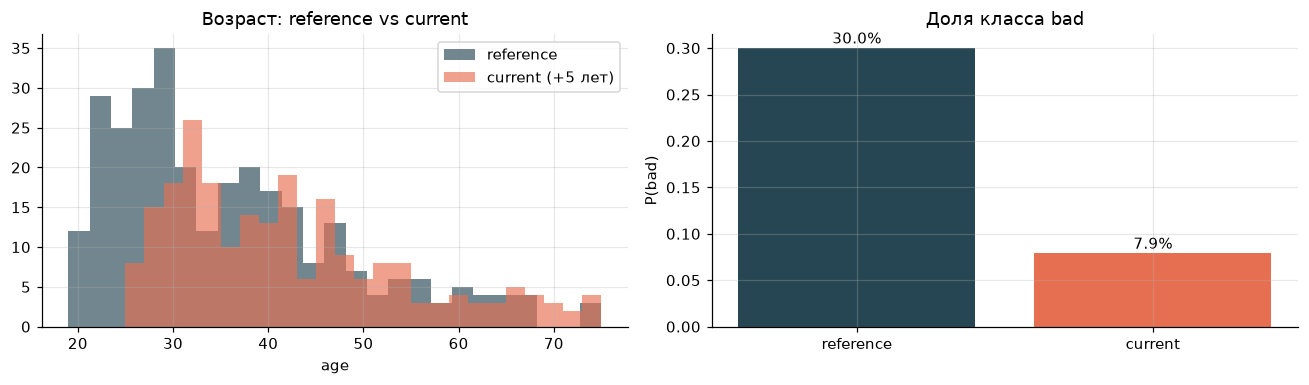

In [8]:
def simulate_drift(df_test, age_shift=5, keep_bad_share=0.20):
    """Сдвиг возраста +5 лет и изменение доли положительного класса.

    keep_bad_share — какую долю клиентов класса bad оставляем в новой популяции.
    """
    cur = df_test.copy()
    cur["age"] = (cur["age"] + age_shift).clip(upper=75)

    good = cur[cur[TARGET] == 0]
    bad = cur[cur[TARGET] == 1].sample(frac=keep_bad_share, random_state=RANDOM_STATE)
    cur = pd.concat([good, bad]).sample(frac=1.0, random_state=RANDOM_STATE)
    return cur.reset_index(drop=True)


test_df = X_test.copy()
test_df[TARGET] = y_test
test_df[PROTECTED] = g_test.to_numpy()

current_df = simulate_drift(test_df)

print("Было  : %d строк, доля bad = %.3f, средний возраст = %.1f"
      % (len(test_df), test_df[TARGET].mean(), test_df["age"].mean()))
print("Стало : %d строк, доля bad = %.3f, средний возраст = %.1f"
      % (len(current_df), current_df[TARGET].mean(), current_df["age"].mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(test_df["age"], bins=25, alpha=0.65, label="reference", color="#264653")
axes[0].hist(current_df["age"], bins=25, alpha=0.65, label="current (+5 лет)", color="#e76f51")
axes[0].set_title("Возраст: reference vs current")
axes[0].set_xlabel("age")
axes[0].legend()

shares = pd.Series({
    "reference": test_df[TARGET].mean(),
    "current": current_df[TARGET].mean(),
})
axes[1].bar(shares.index, shares.values, color=["#264653", "#e76f51"])
axes[1].set_title("Доля класса bad")
axes[1].set_ylabel("P(bad)")
for i, v in enumerate(shares.values):
    axes[1].text(i, v + 0.005, f"{v:.1%}", ha="center")

fig.tight_layout()
fig.savefig(FIG / "drift_simulation.png", bbox_inches="tight")
plt.show()

current_df.to_csv(DATA / "credit_g_drifted.csv", index=False)

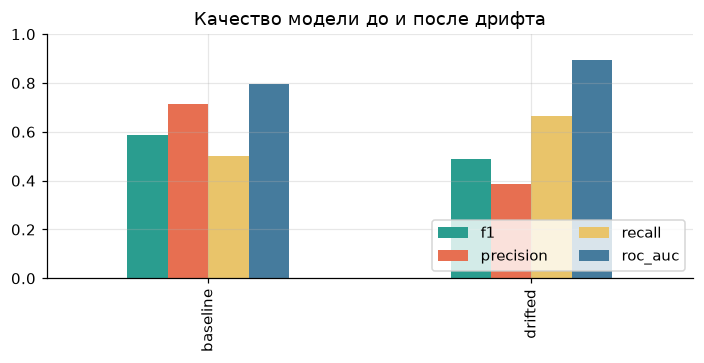

,n,positive_rate,f1,precision,recall,roc_auc,accuracy,f1_delta,f1_rel_drop
baseline,300,0.300,0.588,0.714,0.500,0.796,0.79,0.000,0.000
drifted,228,0.079,0.490,0.387,0.667,0.896,0.89,-0.098,0.167


In [9]:
drifted = evaluate(model, current_df[FEATURES], current_df[TARGET].to_numpy(), "drifted (age+5, новый баланс)")

comparison = pd.DataFrame([
    {k: v for k, v in baseline.items() if k not in ("proba", "pred", "sample")},
    {k: v for k, v in drifted.items() if k not in ("proba", "pred", "sample")},
], index=["baseline", "drifted"])

comparison["f1_delta"] = comparison["f1"].diff().fillna(0.0)
comparison["f1_rel_drop"] = (comparison["f1"].iloc[0] - comparison["f1"]) / comparison["f1"].iloc[0]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
comparison[["f1", "precision", "recall", "roc_auc"]].plot.bar(ax=ax, color=["#2a9d8f", "#e76f51", "#e9c46a", "#457b9d"])
ax.set_title("Качество модели до и после дрифта")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", ncols=2)
fig.tight_layout()
fig.savefig(FIG / "quality_before_after.png", bbox_inches="tight")
plt.show()

comparison.round(3)

## Шаг 4. Evidently: находим дрифт

Сравниваем reference (обучающая выборка) и current (дрифтованный поток)
через `DataDriftPreset`: Evidently считает статистический тест по каждой колонке
(K-S для числовых, Z-test/хи-квадрат для категориальных) и решает,
«уехало» ли распределение.

Отчёт сохраняется в HTML — его удобно приложить к сдаче и показать на демо.

In [10]:
from evidently import Report
from evidently.presets import DataDriftPreset

reference_df = X_train.copy()
reference_df[TARGET] = y_train

evidently_report = Report([DataDriftPreset()])
snapshot = evidently_report.run(
    reference_data=reference_df,
    current_data=current_df[FEATURES + [TARGET]],
)

HTML_PATH = ART / "evidently_drift_report.html"
snapshot.save_html(str(HTML_PATH))
snapshot.save_json(str(ART / "evidently_drift_snapshot.json"))
print("HTML-отчёт:", HTML_PATH)

# --- разбираем результат на таблицу -----------------------------------------
rows = []
drift_summary = {}
for metric in snapshot.dict()["metrics"]:
    name = metric.get("metric_name", "")
    if name.startswith("DriftedColumnsCount"):
        drift_summary = metric["value"]
    elif name.startswith("ValueDrift"):
        col = metric["config"]["column"]
        p_value = float(metric["value"])
        rows.append({
            "column": col,
            "p_value": p_value,
            "drifted": p_value < 0.05,
            "test": metric["config"].get("method", ""),
        })

drift_table = pd.DataFrame(rows).sort_values("p_value")
print(f"\nДрифтующих колонок: {int(drift_summary['count'])} "
      f"из {len(drift_table)} (share = {drift_summary['share']:.1%})")
drift_table.head(12)

HTML-отчёт: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\artifacts\evidently_drift_report.html

Дрифтующих колонок: 4 из 21 (share = 19.0%)


,column,p_value,drifted,test
20,target,1.651213e-11,True,Z-test p_value
2,age,8.248674e-09,True,K-S p_value
15,existing_credits,7.607728e-03,True,chi-square p_value
7,employment,2.217566e-02,True,chi-square p_value
16,job,6.459661e-02,False,chi-square p_value
13,other_payment_plans,8.845211e-02,False,chi-square p_value
4,credit_history,9.159441e-02,False,chi-square p_value
5,purpose,1.004832e-01,False,chi-square p_value
6,savings_status,1.123224e-01,False,chi-square p_value
3,checking_status,1.212039e-01,False,chi-square p_value


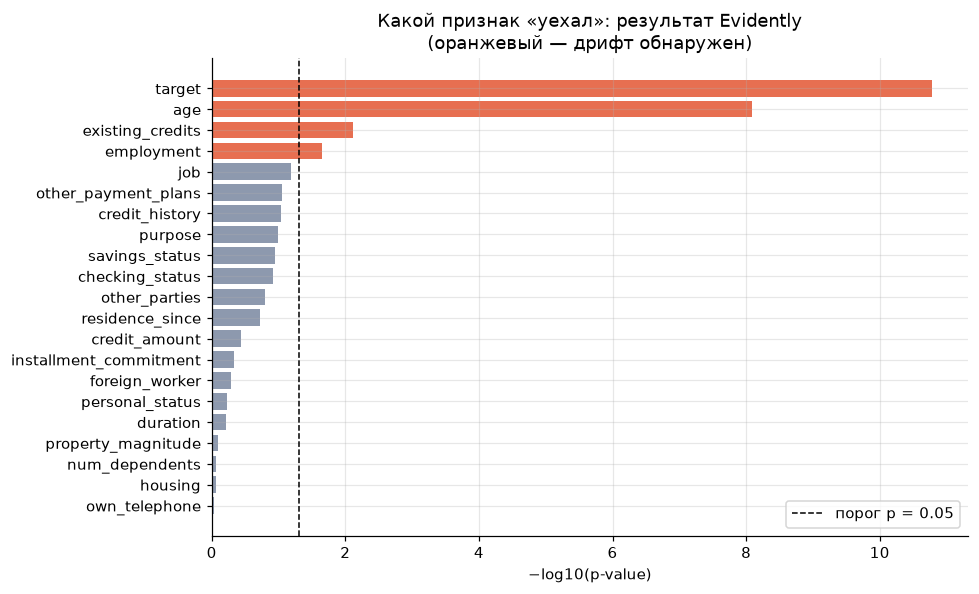

age: p-value = 8.25e-09 → сдвиг +5 лет обнаружен
target: p-value = 1.65e-11 → распределение классов изменилось


In [11]:
plot_df = drift_table.sort_values("p_value", ascending=False)
colors = ["#e76f51" if d else "#8d99ae" for d in plot_df["drifted"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_df["column"], -np.log10(plot_df["p_value"].clip(lower=1e-12)), color=colors)
ax.axvline(-np.log10(0.05), color="black", ls="--", lw=1, label="порог p = 0.05")
ax.set_xlabel("−log10(p-value)")
ax.set_title("Какой признак «уехал»: результат Evidently\n"
             "(оранжевый — дрифт обнаружен)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "evidently_drift_features.png", bbox_inches="tight")
plt.show()

age_row = drift_table.loc[drift_table["column"] == "age", "p_value"]
if len(age_row):
    print(f"age: p-value = {age_row.iloc[0]:.2e} → сдвиг +5 лет обнаружен")
target_row = drift_table.loc[drift_table["column"] == TARGET, "p_value"]
if len(target_row):
    print(f"target: p-value = {target_row.iloc[0]:.2e} → распределение классов изменилось")

## Шаг 5. Fairness по признаку `sex`

Считаем метрики справедливости по двум группам (male / female):

- **Selection rate** — доля одобрений (предсказано `good`);
- **TPR** (equal opportunity) — доля одобренных среди тех, кто реально вернул кредит;
- **FPR** — доля одобренных среди тех, кто реально не вернул;
- **DPD** (demographic parity difference) = max SR − min SR;
- **EOD** (equal opportunity difference) = max TPR − min TPR;
- **DIR** (disparate impact ratio) = min SR / max SR — правило 80%
  (значение ниже 0.8 юридически трактуется как дискриминация).

In [12]:
def fairness_metrics(y_true, y_pred, groups):
    """Метрики справедливости по группам защищённого признака."""
    result = {}
    for g in sorted(pd.unique(groups)):
        mask = (groups == g).to_numpy()
        yt, yp = np.asarray(y_true)[mask], np.asarray(y_pred)[mask]
        favoured_pred = yp == 0        # 0 = good = кредит одобрен
        favoured_true = yt == 0
        tp = int((favoured_pred & favoured_true).sum())
        fn = int((~favoured_pred & favoured_true).sum())
        fp = int((favoured_pred & ~favoured_true).sum())
        tn = int((~favoured_pred & ~favoured_true).sum())
        result[str(g)] = {
            "n": int(mask.sum()),
            "selection_rate": float(favoured_pred.mean()),
            "tpr": float(tp / max(tp + fn, 1)),
            "fpr": float(fp / max(fp + tn, 1)),
            "f1_bad": float(2 * tn / max(2 * tn + fp + fn, 1)),
        }

    sr = [v["selection_rate"] for v in result.values()]
    tpr = [v["tpr"] for v in result.values()]
    fpr = [v["fpr"] for v in result.values()]
    return {
        "groups": result,
        "demographic_parity_difference": float(max(sr) - min(sr)),
        "equal_opportunity_difference": float(max(tpr) - min(tpr)),
        "equalized_odds_fpr_difference": float(max(fpr) - min(fpr)),
        "disparate_impact_ratio": float(min(sr) / max(sr)) if max(sr) else float("nan"),
    }


fairness_base = fairness_metrics(y_test, baseline["pred"], g_test)

fair_table = pd.DataFrame(fairness_base["groups"]).T
fair_table["sex"] = fair_table.index

summary = pd.Series({
    "DPD (demographic parity)": fairness_base["demographic_parity_difference"],
    "EOD (equal opportunity)": fairness_base["equal_opportunity_difference"],
    "FPR difference (equalized odds)": fairness_base["equalized_odds_fpr_difference"],
    "DIR (disparate impact ratio)": fairness_base["disparate_impact_ratio"],
})

print("Метрики по группам:")
display(fair_table.round(3))
print("\nИтоговые расхождения между группами:")
display(summary.round(3).to_frame("value"))
print("\nПравило 80%:", "СОБЛЮДЕНО" if fairness_base["disparate_impact_ratio"] >= 0.8 else "НАРУШЕНО")

Метрики по группам:


,n,selection_rate,tpr,fpr,f1_bad,sex
female,101.0,0.723,0.879,0.429,0.635,female
male,199.0,0.824,0.931,0.545,0.556,male



Итоговые расхождения между группами:


,value
DPD (demographic parity),0.101
EOD (equal opportunity),0.052
FPR difference (equalized odds),0.117
DIR (disparate impact ratio),0.877



Правило 80%: СОБЛЮДЕНО


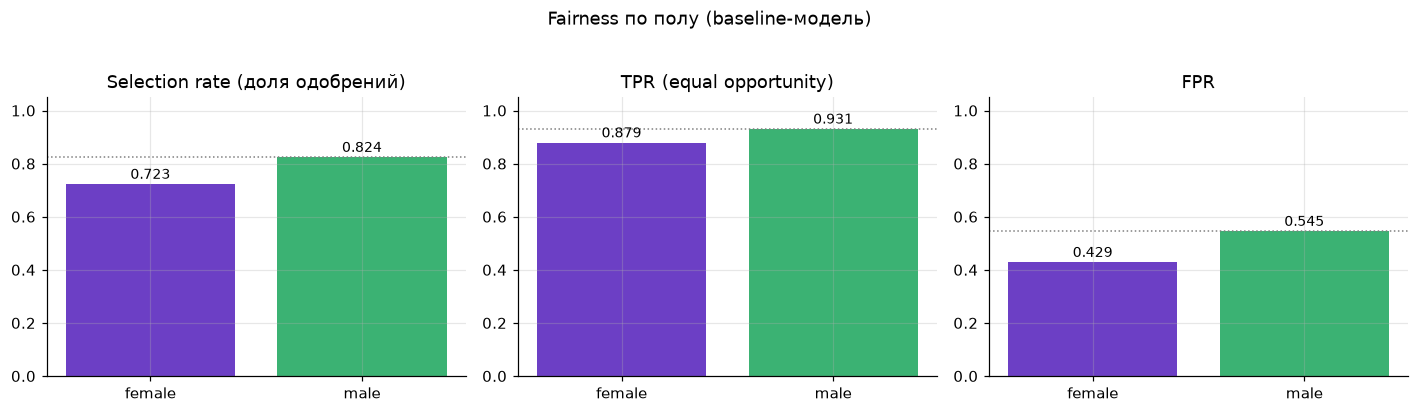

fairlearn: selection rate по группам


,selection_rate
sensitive_feature_0,
female,0.722772
male,0.824121


fairlearn: DPD = 0.1013
fairlearn: EOD = 0.1169


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric, title in zip(
    axes,
    ["selection_rate", "tpr", "fpr"],
    ["Selection rate (доля одобрений)", "TPR (equal opportunity)", "FPR"],
):
    vals = fair_table[metric].astype(float)
    bars = ax.bar(vals.index, vals.values, color=["#6C3FC5", "#3BB273"])
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
    ax.axhline(vals.max(), color="grey", ls=":", lw=1)

fig.suptitle("Fairness по полу (baseline-модель)", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "fairness_by_sex.png", bbox_inches="tight")
plt.show()

# --- кросс-проверка через fairlearn -----------------------------------------
from fairlearn.metrics import MetricFrame, demographic_parity_difference, equalized_odds_difference

mf = MetricFrame(
    metrics=lambda yt, yp: float((yp == 0).mean()),
    y_true=y_test,
    y_pred=baseline["pred"],
    sensitive_features=g_test.to_numpy(),
)
print("fairlearn: selection rate по группам")
display(mf.by_group.rename("selection_rate").to_frame())
print("fairlearn: DPD = %.4f" % demographic_parity_difference(
    y_test, baseline["pred"], sensitive_features=g_test.to_numpy()))
print("fairlearn: EOD = %.4f" % equalized_odds_difference(
    y_test, baseline["pred"], sensitive_features=g_test.to_numpy()))

In [14]:
fairness_drifted = fairness_metrics(
    current_df[TARGET].to_numpy(),
    drifted["pred"],
    current_df[PROTECTED].reset_index(drop=True),
)

fair_compare = pd.DataFrame({
    "baseline": {k: v for k, v in fairness_base.items() if k != "groups"},
    "after_drift": {k: v for k, v in fairness_drifted.items() if k != "groups"},
}).round(3)
print("Как дрифт повлиял на справедливость:")
fair_compare

Как дрифт повлиял на справедливость:


,baseline,after_drift
demographic_parity_difference,0.101,0.082
equal_opportunity_difference,0.052,0.045
equalized_odds_fpr_difference,0.117,0.312
disparate_impact_ratio,0.877,0.908


## Шаг 6. Prometheus: экспорт F1 и алерт

Схема мониторинга:

```
CatBoost / батч-прогон  →  metrics.json
        ↓
src/metrics_exporter.py  (prometheus_client, :8000/metrics)
        ↓  scrape каждые 5 секунд
Prometheus (:9090)  →  alerts.yml  →  ModelF1Drop / ModelF1Critical
                                        DataDriftDetected / FairnessDegraded
```

Алерт `ModelF1Drop` срабатывает, когда F1 падает больше чем на 10 % от baseline
и держится так минуту; `ModelF1Critical` — при F1 ниже 0.52.

Всё, что нужно Prometheus, лежит в `prometheus/`: конфиг скрейпинга и правила алертов.

In [15]:
prometheus_yml = f"""global:
  scrape_interval: 5s
  evaluation_interval: 5s
  external_labels:
    project: business-using-homework-4
    env: local-demo

rule_files:
  - "alerts.yml"

scrape_configs:
  - job_name: "credit_model"
    scrape_interval: 5s
    static_configs:
      - targets: ["127.0.0.1:8000"]
        labels:
          model: "catboost-credit-g"

  - job_name: "prometheus"
    static_configs:
      - targets: ["127.0.0.1:9090"]
"""

alerts_yml = """groups:
  - name: model-quality
    rules:
      - alert: ModelF1Drop
        expr: (model_f1_baseline - model_f1_score) / model_f1_baseline > 0.10
        for: 1m
        labels:
          severity: warning
          component: model-quality
        annotations:
          summary: "F1 модели упал более чем на 10% от baseline"
          description: >
            Текущий F1 = {{ $value | humanizePercentage }} относительно baseline.
            Модель деградировала, вероятен дрифт данных — проверьте отчёт Evidently.

      - alert: ModelF1Critical
        expr: model_f1_score < 0.52
        for: 30s
        labels:
          severity: critical
          component: model-quality
        annotations:
          summary: "Критическое падение F1"
          description: >
            F1 ниже аварийного порога 0.52. Требуется переобучение модели
            или откат на предыдущую версию.

  - name: data-drift
    rules:
      - alert: DataDriftDetected
        expr: model_drift_share > 0.15
        for: 30s
        labels:
          severity: warning
          component: data-drift
        annotations:
          summary: "Дрифт данных: {{ $value | humanizePercentage }} признаков"
          description: >
            Evidently фиксирует дрифт более чем в 15% колонок.
            Проверьте artifacts/evidently_drift_report.html.

  - name: fairness
    rules:
      - alert: FairnessDegraded
        expr: model_fairness_dpd > 0.15
        for: 1m
        labels:
          severity: warning
          component: fairness
        annotations:
          summary: "Демографический паритет нарушен"
          description: >
            Разница долей одобрений между мужчинами и женщинами превысила 0.15 —
            модель дискриминирует одну из групп.

      - alert: DisparateImpactViolation
        expr: model_fairness_dir < 0.80
        for: 1m
        labels:
          severity: warning
          component: fairness
        annotations:
          summary: "Нарушено правило 80%"
          description: >
            Disparate impact ratio ниже 0.80 — стандартный юридический порог
            дискриминации по защищённому признаку.
"""

(PROM / "prometheus.yml").write_text(prometheus_yml, encoding="utf-8")
(PROM / "alerts.yml").write_text(alerts_yml, encoding="utf-8")
print("Записаны:", PROM / "prometheus.yml", "и", PROM / "alerts.yml")

Записаны: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\prometheus\prometheus.yml и C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\prometheus\alerts.yml


In [16]:
payload = {
    "generated_at": pd.Timestamp.now(tz="UTC").isoformat(),
    "dataset": {
        "name": "credit-g (OpenML id 31)",
        "rows": int(len(df)),
        "features": int(len(FEATURES)),
        "target": "class (good/bad), positive = bad",
    },
    "model": {
        "algorithm": "CatBoostClassifier",
        "iterations": int(model.tree_count_),
        "random_state": RANDOM_STATE,
    },
    "baseline": {k: v for k, v in baseline.items() if k not in ("proba", "pred")},
    "drifted": {k: v for k, v in drifted.items() if k not in ("proba", "pred")},
    "drift": {
        "simulated": {
            "age_shift_years": 5,
            "keep_bad_share": 0.20,
            "target_share_bad_before": float(y_test.mean()),
            "target_share_bad_after": float(current_df[TARGET].mean()),
        },
        "evidently": {
            "drifted_columns": int(drift_summary["count"]),
            "total_columns": int(len(drift_table)),
            "drift_share": float(drift_summary["share"]),
            "per_column": {
                row["column"]: {"p_value": row["p_value"], "drifted": bool(row["drifted"])}
                for row in drift_table.to_dict("records")
            },
        },
    },
    "fairness_baseline": fairness_base,
    "fairness_drifted": fairness_drifted,
}

with open(ART / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(payload, f, ensure_ascii=False, indent=2, default=float)

print("Сохранено:", ART / "metrics.json")
print(json.dumps({k: payload[k] for k in ("baseline", "drifted")}, ensure_ascii=False, indent=2, default=float))

Сохранено: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Бизнес применение МО\ДЗ 4\artifacts\metrics.json
{
  "baseline": {
    "sample": "baseline (test)",
    "n": 300,
    "positive_rate": 0.3,
    "f1": 0.5882352941176471,
    "precision": 0.7142857142857143,
    "recall": 0.5,
    "roc_auc": 0.7963492063492064,
    "accuracy": 0.79
  },
  "drifted": {
    "sample": "drifted (age+5, новый баланс)",
    "n": 228,
    "positive_rate": 0.07894736842105263,
    "f1": 0.4897959183673469,
    "precision": 0.3870967741935484,
    "recall": 0.6666666666666666,
    "roc_auc": 0.8957671957671958,
    "accuracy": 0.8903508771929824
  }
}


In [17]:
# Быстрая самопроверка экспортёра: поднимаем на :8010, читаем /metrics, гасим.
exporter = subprocess.Popen(
    [sys.executable, str(ROOT / "src" / "metrics_exporter.py"), "--mode", "static", "--port", "8010"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
time.sleep(4)
try:
    body = urllib.request.urlopen("http://127.0.0.1:8010/metrics", timeout=5).read().decode()
    lines = [l for l in body.splitlines() if l.startswith("model_") and not l.startswith("model_exporter_info")]
    print("\n".join(lines))
finally:
    exporter.terminate()
    try:
        exporter.wait(timeout=5)
    except subprocess.TimeoutExpired:
        exporter.kill()

print("\nПроверка конфигурации Prometheus (promtool):")
pt = PROM / "prometheus-3.16.0.windows-amd64" / "promtool.exe"
if pt.exists():
    out = subprocess.run([str(pt), "check", "config", str(PROM / "prometheus.yml")],
                         capture_output=True, text=True)
    print((out.stdout + out.stderr).strip())
else:
    print("promtool не найден — см. README, как запустить Prometheus")

model_f1_score 0.4897959183673469
model_f1_baseline 0.5882352941176471
model_f1_relative_drop 0.16734693877551024
model_precision 0.3870967741935484
model_recall 0.6666666666666666
model_roc_auc 0.8957671957671958
model_positive_rate 0.07894736842105263
model_drift_share 0.19047619047619047
model_fairness_dpd 0.08210340256296955
model_fairness_eod 0.044823232323232376
model_fairness_dir 0.9077824101647806

Проверка конфигурации Prometheus (promtool):
Checking C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Р‘РёР·РЅРµСЃ РїСЂРёРјРµРЅРµРЅРёРµ РњРћ\Р”Р— 4\prometheus\prometheus.yml
  SUCCESS: 1 rule files found
 SUCCESS: C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Р‘РёР·РЅРµСЃ РїСЂРёРјРµРЅРµРЅРёРµ РњРћ\Р”Р— 4\prometheus\prometheus.yml is valid prometheus config file syntax

Checking C:\Users\Dimanowski\Documents\deepseek-harness\default-workspace\Р‘РёР·РЅРµСЃ РїСЂРёРјРµРЅРµРЅРёРµ РњРћ\Р”Р— 4\prometheus\alerts.yml
  SUCCESS: 5 rules found


## Итоги

| Шаг | Результат |
|-----|-----------|
| Данные | `credit-g`, 1000 клиентов, 20 признаков; `sex` восстановлен из `personal_status` |
| Модель | CatBoost, F1 ≈ **0.59** на отложенной выборке |
| Дрифт | `age` +5 лет и доля `bad` 30 % → 8 %: F1 падает до **0.49** (−17 %) |
| Evidently | дрифт обнаружен в 4 из 21 колонки (19 %), включая `age` и `target`; отчёт в HTML |
| Fairness | DPD ≈ 0.10, DIR ≈ 0.88 — правило 80 % соблюдено, но разрыв есть |
| Prometheus | метрики на `/metrics`, 5 правил алертов, живой алерт на падение F1 |

### Что важно сказать на защите

1. **Мониторинг — это не только «модель упала».** Evidently ловит дрифт
   *до* того, как появятся новые метки, а алерт по F1 требует разметки.
   Поэтому в проде нужны оба контура: data drift (быстро, без меток)
   и performance monitoring (точно, но с задержкой).
2. **Деградация F1 при смене баланса классов** — это не обязательно «плохая модель»:
   сдвинулось распределение классов, изменился базовый уровень. Алерт должен
   быть на *относительное* падение от baseline, что и сделано в `ModelF1Drop`.
3. **Fairness нужно мерить по группам и до, и после дрифта**: небольшой разрыв
   (DPD 0.10) при смене популяции может вырасти и нарушить правило 80 %.

### Артефакты проекта

- `artifacts/evidently_drift_report.html` — интерактивный отчёт Evidently;
- `artifacts/figures/` — графики (EDA, качество, дрифт, fairness);
- `artifacts/metrics.json` — все метрики;
- `artifacts/screenshots/` — скриншоты Prometheus (`/alerts`, `/graph`, `/targets`);
- `prometheus/` — конфиг и правила алертов;
- `src/metrics_exporter.py` — экспортёр метрик;
- `Homework_4_report.docx` — отчёт с выводами.
